# Pramana — CPUC QoE experiment runner

This notebook is the **primary experiment runner** for the CPUC broadband-QoE
study. It drives the NetGent / Agentic-Thin-Waist stack on the lab VM to run
**real, measured** network experiments — solo and multi-app concurrent — then
verifies the results are physically correct and saves a structured dataset
(+ plots) ready for the paper.

### Two ways to describe an experiment
- **DIRECT** *(default, deterministic, no LLM)* — you give app names + explicit
  parameters (bandwidth, latency, loss, AQM, CCA, duration). The notebook drives
  the substrate worker directly: `shape → congestion → capture → run`. This is
  the reliable path and is what the sweeps below use.
- **INTENT** *(natural language)* — you write one plain-English sentence and the
  orchestrator (`:8005`) parses + runs it. Requires the orchestration service to
  be running (it is optional in the compose stack and is often stopped).

### Reporting conventions (enforced in code, not left to the analyst)
- **Never a combined throughput plot.** Every run emits **one throughput plot
  per app**, showing only that app's traffic against the cap, with the average
  and peak drawn and annotated. Title format:
  `Throughput — YouTube — 6 Mbps / 50ms / pfifo`.
- **Video apps plot download only.** For YouTube / Twitch / Vimeo / Tubi the
  upload direction is ACKs; adding it to the download makes a 10 Mbps stream
  read as 11–12 Mbps. Upload is still *measured* and stored — just never summed
  into the download.
- **Conferencing apps plot both directions, separately.** For Zoom and Meet both
  directions carry real media, so each gets its own plot.
- **Multi-app runs are split per app.** One capture is taken at the bottleneck
  and then attributed per app (see below). Per-app numbers are written to
  `record.json` under `per_app_stats`.
- **Every run keeps its PCAP.** The capture is saved next to `record.json` and
  the plots — including for runs that fail shaping verification. It is the raw
  evidence and is never discarded.
- **Plots are generated automatically** when a run finishes. There is no
  separate plotting call to remember.

### How a shared capture is split per app
Two mechanisms, in priority order:

1. **Namespace alias IP** — when the substrate worker assigns each app its own
   source IP (`POST /shape/per_app_marks`), every packet carries the app
   identity in its local endpoint. Exact, no heuristics.
2. **Remote endpoint** — the *currently deployed* worker runs every browser app
   in the same namespace (`ns1`, one source IP), so mechanism 1 is unavailable.
   Instead each remote IP is identified from the plaintext **DNS answers and TLS
   SNI inside the same capture**, then mapped to an app by domain suffix
   (`googlevideo.com` → YouTube, `vimeocdn.com` → Vimeo, …). Measured coverage
   on real concurrent captures: **>97% of bytes**.

Traffic belonging to the *browser* rather than any app under test — Chrome's
component updates and optimization-guide model downloads — is bucketed as
`browser_infra` and kept out of every per-app plot. This is not a rounding
detail: on a real 6 Mbps YouTube+Vimeo capture, **84 MB of 113 MB was Chrome
infrastructure**, against 19 MB of YouTube and 7 MB of Vimeo. A combined plot of
that run would have shown roughly four times the real video throughput.

### What each run measures (network side)
Per app, per direction: `avg / peak / p95 throughput`, `total_mb`,
`stall_seconds` (time under 5% of the cap), `delivered_fraction` (share of the
run with active traffic), and a `served` / `starved` classification —
**served** when peak ≥ 30% of the cap (the app really streamed), **starved**
when peak < 30% (it got almost nothing). Link-level stats and the
`shaping_verified` flag are kept separately, under `network_stats`.

### What gets saved (per run, under `results/pramana_runs/<slug>_<id>/`)
| file | contents |
|---|---|
| `capture.pcap` | raw capture at the bottleneck — always saved |
| `throughput_<app>.png` | one per app (per direction for calls) |
| `qoe_summary_<app>.png` | one per app: stalls, delivered fraction, peak vs avg, verdict |
| `record.json` | config + `network_stats` + `per_app_stats` + artifact paths |

Every run is also appended to `results/pramana_runs/dataset_index.jsonl`.

### Honest limitations of the currently deployed stack
- **Player QoE is not available.** The deployed substrate NetGent is the "v2"
  engine, whose actions are `go_to_url / wait / click_element / …` with **no
  `start_stats_logging`** — so resolution / rebuffer rate / dropped frames
  aren't produced. Every record is tagged **`player_qoe_available: false`**, and
  the QoE summary plot says so on its face. The metrics it *does* show are
  network-derived proxies computed from the PCAP. When the team deploys the
  NetGent build with stats logging, that flag flips to `true` and the same plot
  automatically grows a player-side panel.
- Queue-depth (`qtrace`) time series are **not** available (deployed
  `main_local` has no `/qtrace`).
- Latency/loss are applied **link-wide** (netem), not per-flow.

> **Where to run:** run this notebook **on the lab VM** (or with an SSH tunnel to
> ports 8002–8005). See the last cell for exact instructions.


## 0 · Setup & health check

Loads the helper module and probes the four services the notebook depends on.
`DIRECT` mode needs substrate (`:8002`) + telemetry (`:8004`). `INTENT` mode
additionally needs the orchestrator (`:8005`).

If you are **not** running on the VM host, set the service URLs / capture dir to
match your SSH tunnel before running (see the commented lines).

In [1]:
import pramana_helpers as ph
from pramana_helpers import ExperimentConfig, run_experiment, run_sweep

# ── Where the services live ──────────────────────────────────────────────
# Defaults assume this notebook runs ON the lab VM, where the stack is on
# localhost. Everything is environment-driven, so a different host needs env
# vars, not code edits:
#   PRAMANA_SUBSTRATE_URL / _NETGENT_URL / _TELEMETRY_URL / _ORCH_URL
#   PRAMANA_COLLECTOR_IMAGE   (default video-qoe-collector:latest)
#   PRAMANA_SUBSTRATE_CONTAINER, PRAMANA_DOCKER, PRAMANA_RESULTS_DIR
#
# `shared.apps` / `shared.qoe` come from this same repo — nothing to configure.
print(ph.shared_repo_status())
print("results ->", ph.RESULTS_ROOT)

# Correctness knobs.
ph.SHAPING_TOLERANCE = 0.15   # measured avg throughput must be within ±15% of cap
ph.STRICT_SHAPING = True      # raise (don't save trusted data) if shaping fails

ph.stack_health()


shared.apps + shared.qoe loaded from /home/student/sthanav-agentic-thin-waist (9 apps)
results -> /home/student/sthanav-agentic-thin-waist/experiments/pramana/results/pramana_runs


  substrate (:8002)      up
  netgent (:8003)        up
  telemetry (:8004)      up
  orchestrator (:8005)   up


{'substrate (:8002)': 'up',
 'netgent (:8003)': 'up',
 'telemetry (:8004)': 'up',
 'orchestrator (:8005)': 'up'}

## 1 · Choose your experiment — DIRECT or INTENT

Pick **one** path per run. The DIRECT block is active by default; comment it out
and uncomment the INTENT block to use natural language instead.

**Parameters you can set** (all recorded in the dataset):
- **apps**: `youtube`, `twitch`, `vimeo`, `tubi`, `zoom`, `meet`, `wget`
  (one app = solo, several = concurrent on one shared bottleneck)
- **bandwidth_mbps**: 1, 3, 6, 10, 25, 50, 100, 200
- **latency_ms**: 0, 15, 25, 50, 100, 200
- **loss_pct**: 0, 0.1, 0.5, 1, 2, 5
- **aqm**: `pfifo`, `fq_codel`, `codel`
- **cca**: `cubic`, `bbr`, `reno`
- **controller**: `playwright` or `pyautogui` (recorded; deployed browser path is Playwright)
- **duration_s**, **trial**, **buffer_packets**
- **app_urls**: per-app URL overrides — **required** for `zoom` / `meet`
  (a join URL) and recommended for `twitch` (a live channel)


In [2]:
# ═══════════════════════════════════════════════════════════════════════
#  OPTION A — DIRECT (deterministic, no LLM).  ◀ active by default
# ═══════════════════════════════════════════════════════════════════════
EXECUTION_MODE = "direct"
CONTROLLER = "playwright"          # "playwright" | "pyautogui"

cfg = ExperimentConfig(
    apps=["tubi"],              # one app = solo; more = concurrent
    bandwidth_mbps=6,
    latency_ms=50,
    loss_pct=0,
    aqm="pfifo",
    cca="cubic",
    duration_s=60,
    controller=CONTROLLER,
    trial=1,
)

# ═══════════════════════════════════════════════════════════════════════
#  OPTION B — INTENT (natural language, needs orchestrator :8005).
#  Comment out the block above and uncomment these two lines to use it.
# ═══════════════════════════════════════════════════════════════════════
# EXECUTION_MODE = "intent"
# INTENT = ("Run YouTube on a 6 Mbps bottleneck with 50 ms latency for 60 "
#           "seconds using cubic congestion control and a pfifo queue.")

print(f"Mode = {EXECUTION_MODE}")
if EXECUTION_MODE == "direct":
    print("Experiment:", cfg.make_slug())
    for a in cfg.apps:
        print(f"  {a}: plotting {', '.join(ph.app_plot_directions(a))}")


Mode = direct
Experiment: tubi_6mbps_50ms_0pct_pfifo_cubic_solo_t1
  tubi: plotting download


## 2 · Baseline — fast reference set  ·  ~12 min  ·  **runs by default**

The standard scenarios we treat as reference comparisons: a bandwidth ladder at
one representative latency (50 ms), the same tier run solo and concurrently, so
contention is measurable. Five runs at ~2.3 min each.

Run this first — to sanity-check the pipeline, or to get quick reference numbers.
For the full parameter matrix see **§4**, which is opt-in and takes ~45 min.

Every run here goes through exactly the same capture, per-app attribution and
`record.json` path as the full sweep — nothing is shortened for speed except the
number of scenarios. Validate with `validate_runs.py` the same way (see §7).


In [3]:
# ── APP-COMBO MATRIX: 4 combos x the baseline bandwidth ladder ────────────
# Everything except apps and bandwidth is held at baseline defaults.
LADDER      = [3, 6, 10, 50]          # Mbps
COMBOS      = [
    ["youtube", "twitch"],
    ["vimeo", "twitch"],
    ["tubi", "twitch"],
    ["youtube", "vimeo", "twitch"],
]
MATRIX_LATENCY_MS = 50
MATRIX_DURATION_S = 120

baseline_records = []
matrix_records   = []
record = None
concurrent_cfg = None
concurrent_record = None

if EXECUTION_MODE == "direct":
    for _apps in COMBOS:
        for _bw in LADDER:
            print(f"\n===== {'+'.join(_apps)} @ {_bw} Mbps / {MATRIX_LATENCY_MS} ms "
                  f"/ {MATRIX_DURATION_S}s =====", flush=True)
            concurrent_cfg = ExperimentConfig(
                apps=_apps, bandwidth_mbps=_bw,
                latency_ms=MATRIX_LATENCY_MS, loss_pct=0,
                aqm="pfifo", cca="cubic", duration_s=MATRIX_DURATION_S,
                controller=CONTROLLER, tag="combo_matrix",
            )
            try:
                concurrent_record = run_experiment(concurrent_cfg, mode="direct")
            except Exception as exc:
                print(f"  ! run failed: {type(exc).__name__}: {exc}", flush=True)
                concurrent_record = None
            if concurrent_record:
                matrix_records.append(concurrent_record)
    baseline_records = list(matrix_records)
    record = matrix_records[-1] if matrix_records else None
    print(f"\nmatrix complete: {len(matrix_records)} runs", flush=True)
else:
    print("matrix cell requires EXECUTION_MODE == 'direct'")



===== youtube+twitch @ 3 Mbps / 50 ms / 120s =====


▶ DIRECT run: youtube+twitch_3mbps_50ms_0pct_pfifo_cubic_concurrent2_t1
  cap=3Mbps lat=50ms loss=0% aqm=pfifo cca=cubic dur=120s apps=['youtube', 'twitch']
  • shaping ...
  • capture on veth2 (auto-stop 180s) ...


  • real QoE collector for ['youtube', 'twitch'] ...
    · driving 2 browser app(s) in real Chrome inside ns1 (youtube, twitch) ...


      [youtube] summary: 116 samples written to /out/youtube_stats.jsonl | current_time_secs range=[9.427581, 128.509945] | advanced=True | final_resolution=854x480
      [twitch] summary: 116 samples written to /out/twitch_stats.jsonl | current_time_secs range=[32.072975, 142.23047] | advanced=True | final_resolution=1280x720
      _XSERVTransSocketUNIXCreateListener: mkdir(/tmp/.X11-unix) failed, errno = 17
      _XSERVTransMakeAllCOTSServerListeners: failed to create listener for unix
  • finalising capture + downloading pcap ...


  • pcap saved → /home/student/sthanav-agentic-thin-waist/experiments/pramana/results/pramana_runs/youtube+twitch_3mbps_50ms_0pct_pfifo_cubic_concurrent2_t1_b2164ec416/capture.pcap (66.7 MB)


...

    method=remote_hostname  local=['172.16.1.1']  85.2% of bytes attributed
      vimeo                79.17 MB
      twitch               66.29 MB
      other                26.66 MB
      youtube               6.10 MB
      browser_infra         1.53 MB
    · youtube: served (dl avg 0.32 / peak 12.47 Mbps, delivered 5%)
    · vimeo: served (dl avg 4.15 / peak 44.87 Mbps, delivered 24%)
    · twitch: served (dl avg 3.44 / peak 9.64 Mbps, delivered 83%)
  • generating per-app plots ...


    · youtube (download): throughput + qoe_summary saved [starved, avg 0.32 Mbps]


    · vimeo (download): throughput + qoe_summary saved [served, avg 4.15 Mbps]


    · twitch (download): throughput + qoe_summary saved [starved, avg 3.44 Mbps]


  ✓ saved → /home/student/sthanav-agentic-thin-waist/experiments/pramana/results/pramana_runs/youtube+vimeo+twitch_50mbps_50ms_0pct_pfifo_cubic_concurrent3_t1_58e7eb0e2c
    pcap: capture.pcap | plots: 6 | record.json

matrix complete: 16 runs


## 3 · Multi-app concurrent run (contention on a shared link)

The baseline in §2 already produced this run — YouTube + Vimeo sharing one
6 Mbps / 50 ms bottleneck — so nothing re-runs here. The cells below inspect it:
per-app plots, the attribution split, and real player-side QoE.


In [4]:
# The concurrent run came from the baseline cell (§2); no second run needed.
# `concurrent_cfg` / `concurrent_record` are already defined there.
assert concurrent_record, "run the baseline cell (§2) first"
print(f"inspecting: {concurrent_record['slug']}  "
      f"({'+'.join(concurrent_cfg.apps)} @ {concurrent_cfg.bandwidth_mbps} Mbps / "
      f"{concurrent_cfg.latency_ms} ms)")


inspecting: youtube+vimeo+twitch_50mbps_50ms_0pct_pfifo_cubic_concurrent3_t1  (youtube+vimeo+twitch @ 50 Mbps / 50 ms)


Run folder: /home/student/sthanav-agentic-thin-waist/experiments/pramana/results/pramana_runs/youtube+vimeo+twitch_50mbps_50ms_0pct_pfifo_cubic_concurrent3_t1_58e7eb0e2c

  plot_combined_throughput = False
  per_app_plots            = True
  player_qoe_available     = True
  pcap saved               = True  (/home/student/sthanav-agentic-thin-waist/experiments/pramana/results/pramana_runs/youtube+vimeo+twitch_50mbps_50ms_0pct_pfifo_cubic_concurrent3_t1_58e7eb0e2c/capture.pcap)
  attribution method       = remote_hostname  (85.2% of bytes attributed)

Per-app results:
  youtube   served    avg 0.315 Mbps  peak 12.472 Mbps  stalls 144.0s  delivered 0.046
  vimeo     served    avg 4.151 Mbps  peak 44.865 Mbps  stalls 114.0s  delivered 0.245
  twitch    served    avg 3.445 Mbps  peak 9.636 Mbps  stalls 25.0s  delivered 0.834

Files written:
  capture.pcap
  collector.log
  qoe
  qoe_summary_twitch.png
  qoe_summary_vimeo.png
  qoe_summary_youtube.png
  record.json
  throughput_twitch.png
 

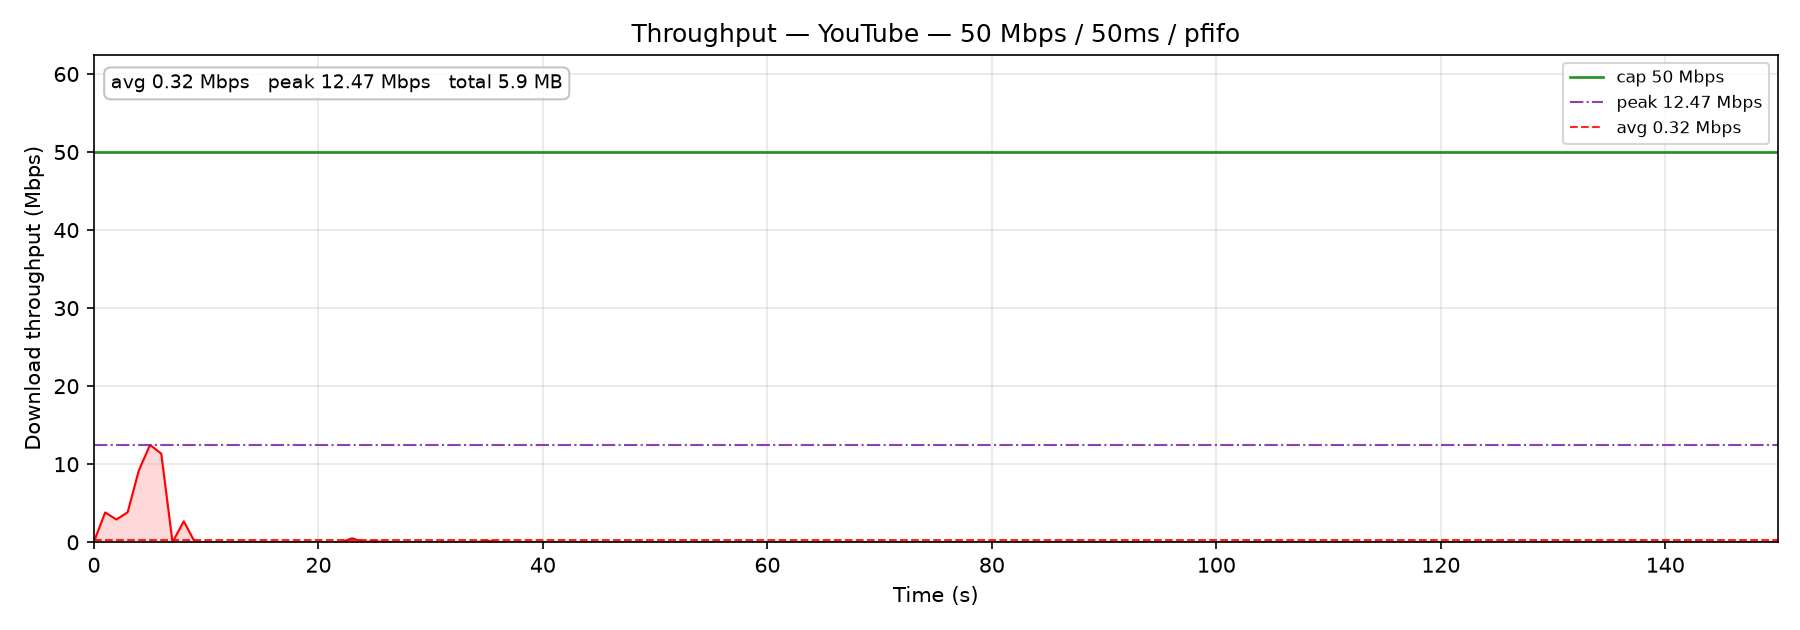

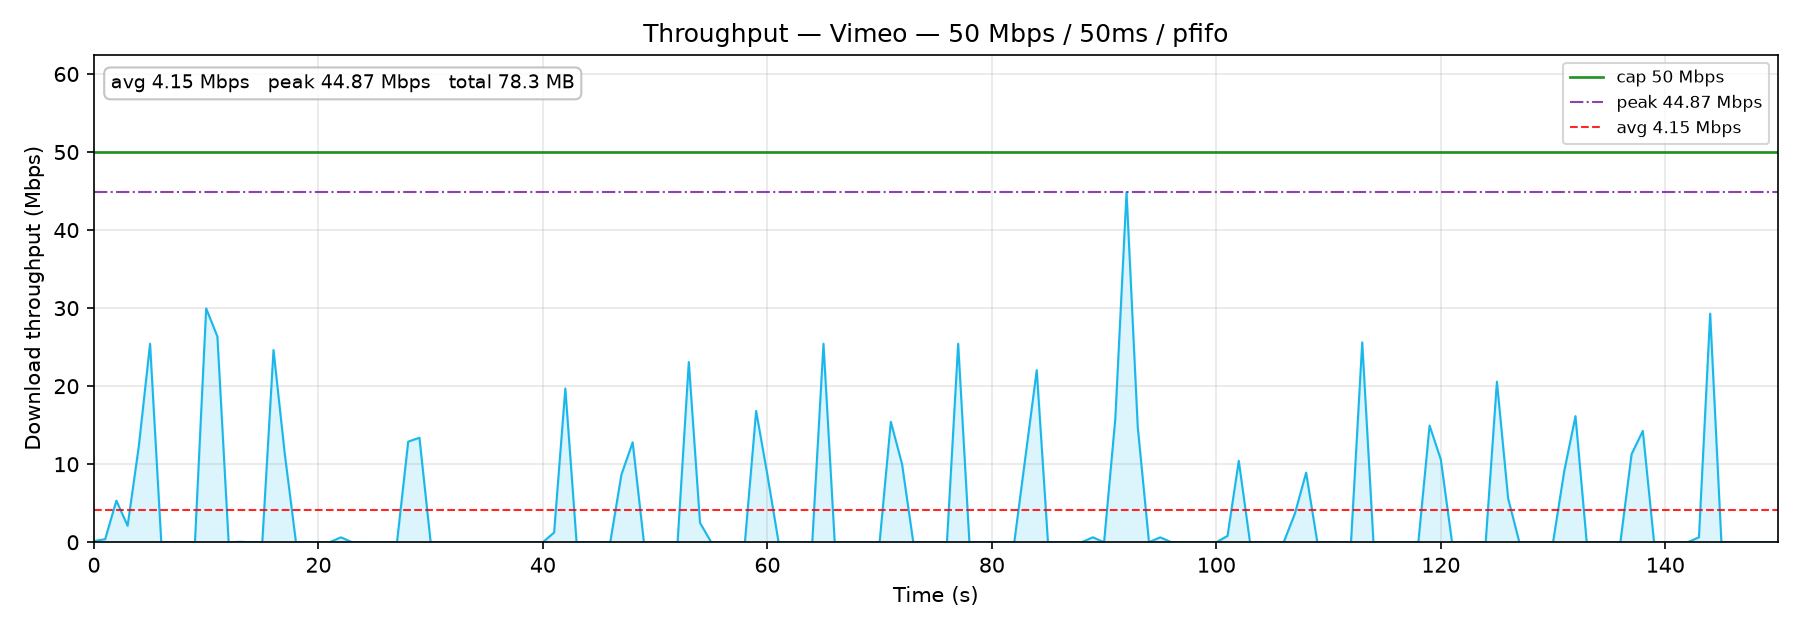

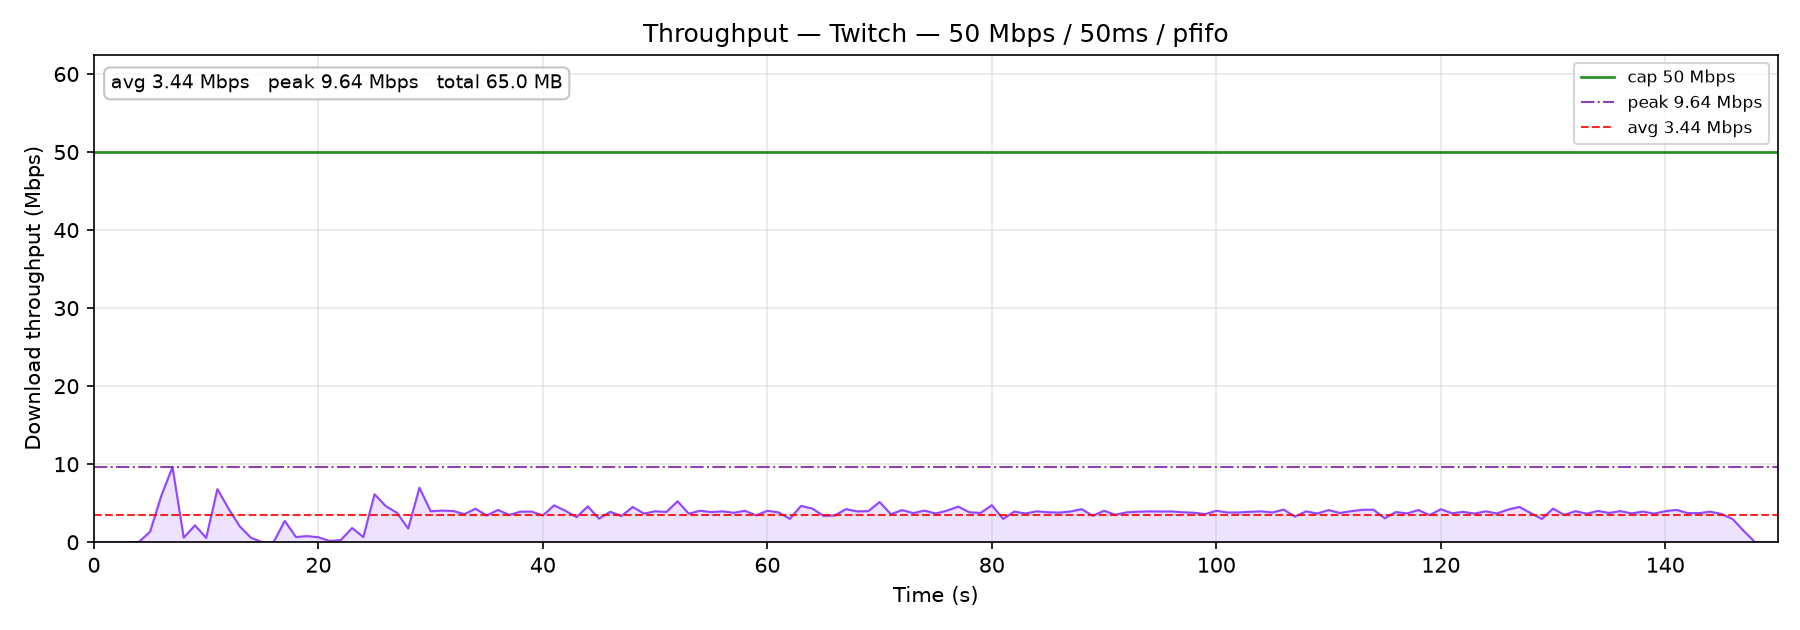

In [5]:
# ── Verify the per-app split: one plot per app, none combined ────────────
from pathlib import Path
from IPython.display import Image, display

run_dir = Path(concurrent_record["artifacts"]["dir"])
print(f"Run folder: {run_dir}\n")

print(f"  plot_combined_throughput = {concurrent_record['plot_combined_throughput']}")
print(f"  per_app_plots            = {concurrent_record['per_app_plots']}")
print(f"  player_qoe_available     = {concurrent_record['player_qoe_available']}")
print(f"  pcap saved               = {concurrent_record['artifacts']['pcap_saved']}"
      f"  ({run_dir / 'capture.pcap'})")
print(f"  attribution method       = "
      f"{concurrent_record['limitations']['per_app_attribution_method']}"
      f"  ({100 * concurrent_record['limitations']['attributed_byte_fraction']:.1f}%"
      f" of bytes attributed)\n")

print("Per-app results:")
for app, st in concurrent_record["per_app_stats"].items():
    dl = st["download"]
    print(f"  {app:9s} {st['classification']:9s} "
          f"avg {dl['avg_throughput_mbps']} Mbps  peak {dl['peak_throughput_mbps']} Mbps  "
          f"stalls {dl['stall_seconds']}s  delivered {dl['delivered_fraction']}")

print("\nFiles written:")
for f in sorted(run_dir.iterdir()):
    print(f"  {f.name}")

# Show each app's throughput plot — separately, never overlaid.
for app in concurrent_cfg.apps:
    png = run_dir / f"throughput_{app}.png"
    if png.exists():
        display(Image(filename=str(png)))


### QoE proxy metrics (no player-side logging required)

The deployed NetGent build has no player stats, so resolution / rebuffer rate /
dropped frames genuinely cannot be measured — every record says so with
`player_qoe_available: false`. What the PCAP *can* honestly support is plotted
in `qoe_summary_<app>.png`:

- **throughput over time** — that app only, download only for video
- **stall time** — shaded spans where throughput fell below 5% of the cap
- **delivered fraction** — % of the run that had active traffic, annotated
- **peak vs average** — two horizontal reference lines
- **traffic classification** — `served` (peak ≥ 30% of cap) or `starved`

> Note: the capture starts before the browser has finished warming up, so the
> pre-playback period counts toward `stall_seconds` and against
> `delivered_fraction`. Read them relative to each other across runs at the same
> duration rather than as absolute player rebuffering.

When the stats-logging NetGent build is deployed, flip `player_qoe_available`
to `true` and pass the player series to `generate_run_plots(..., player_qoe=...)`
— the same figure grows a second panel with the real player-side metrics.


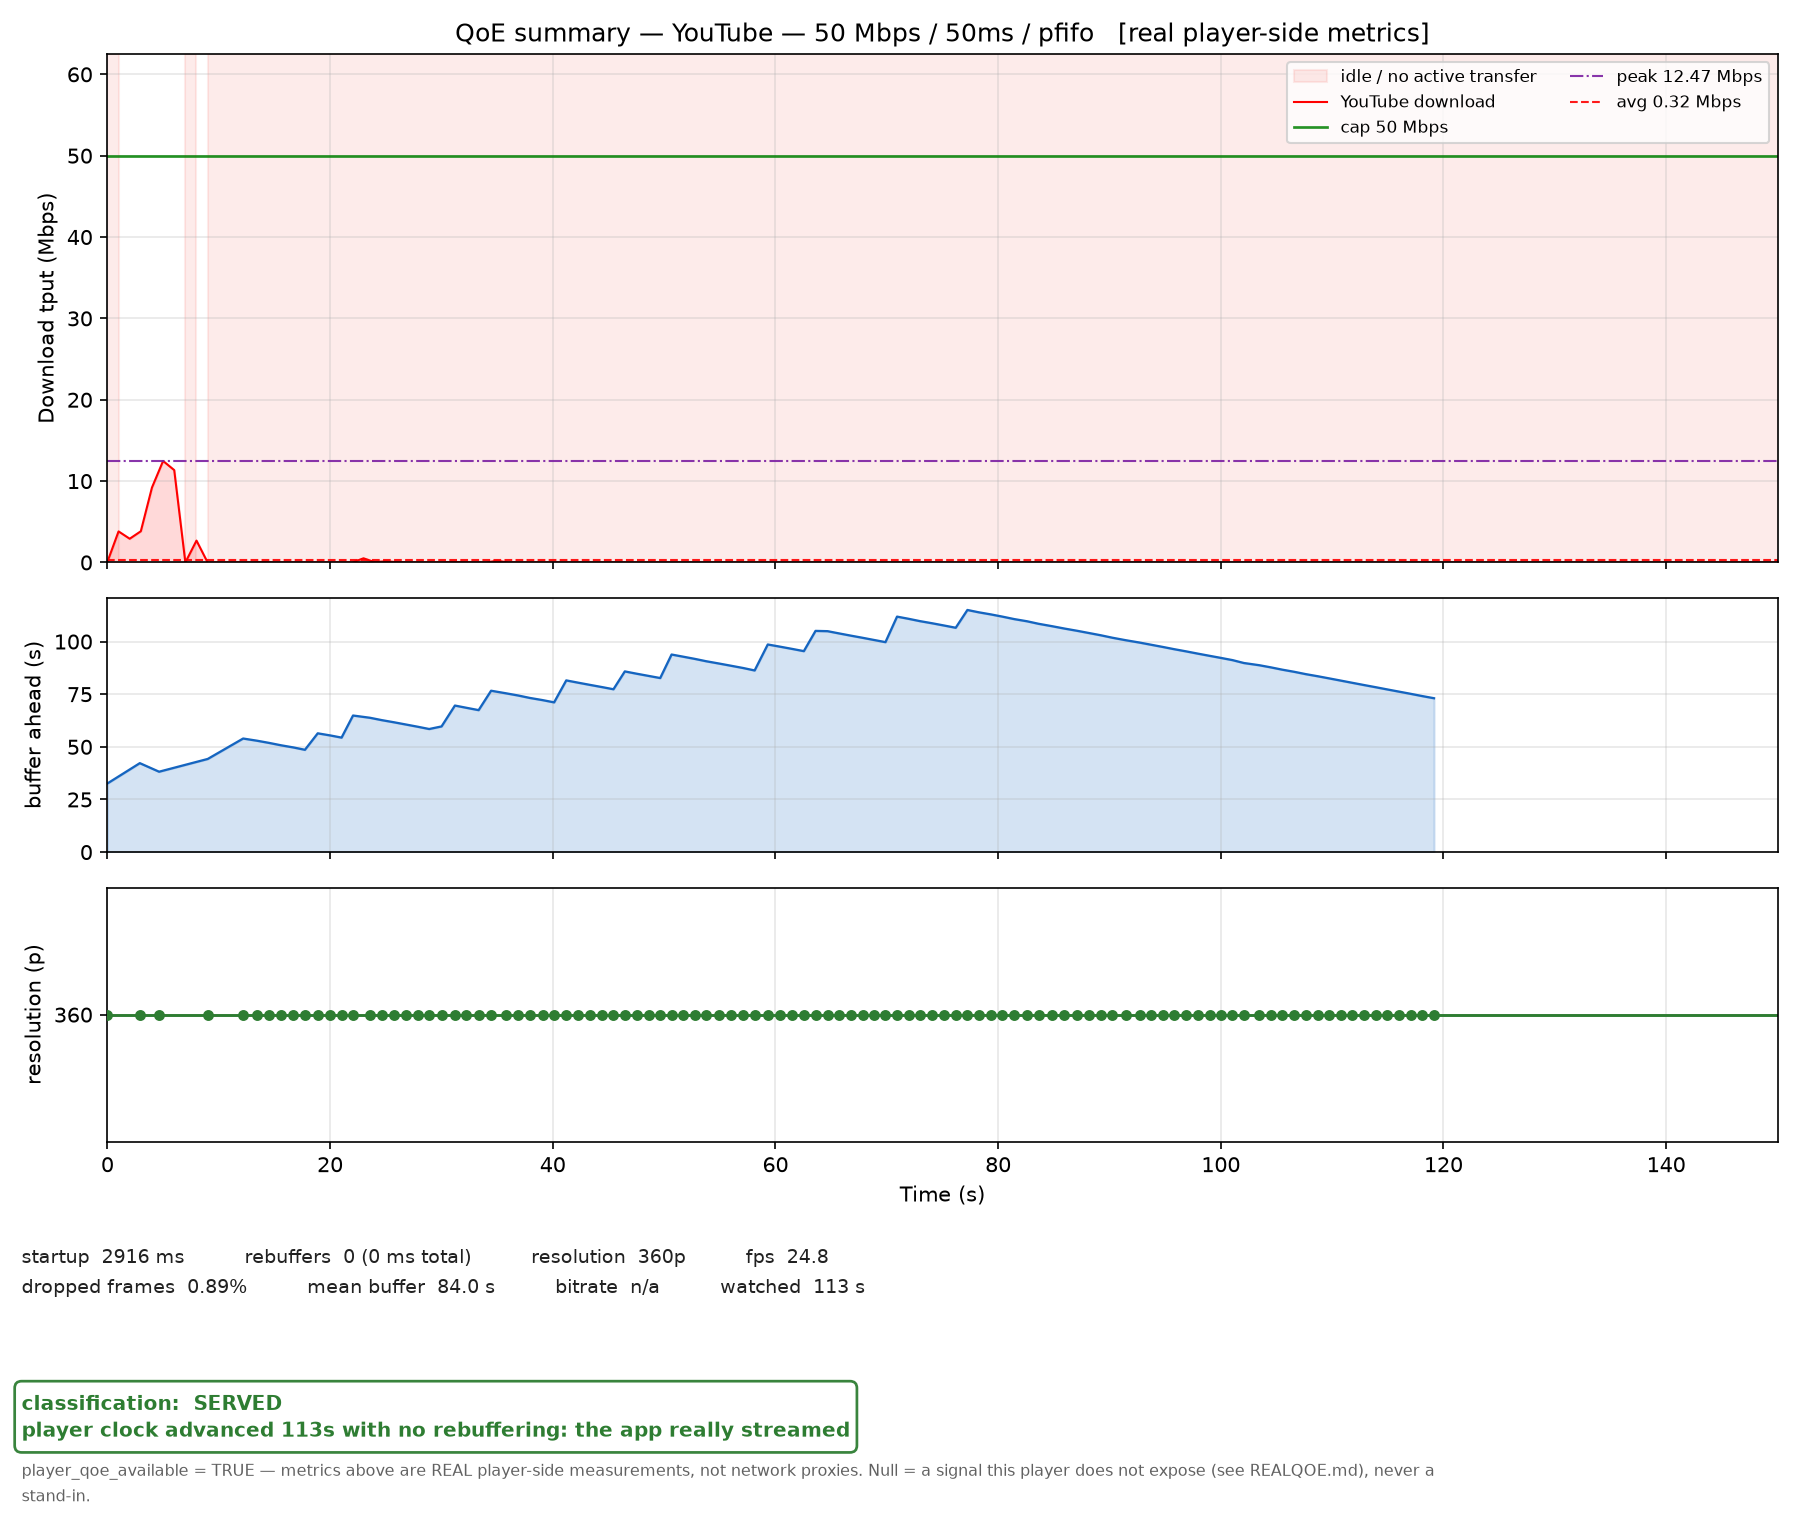

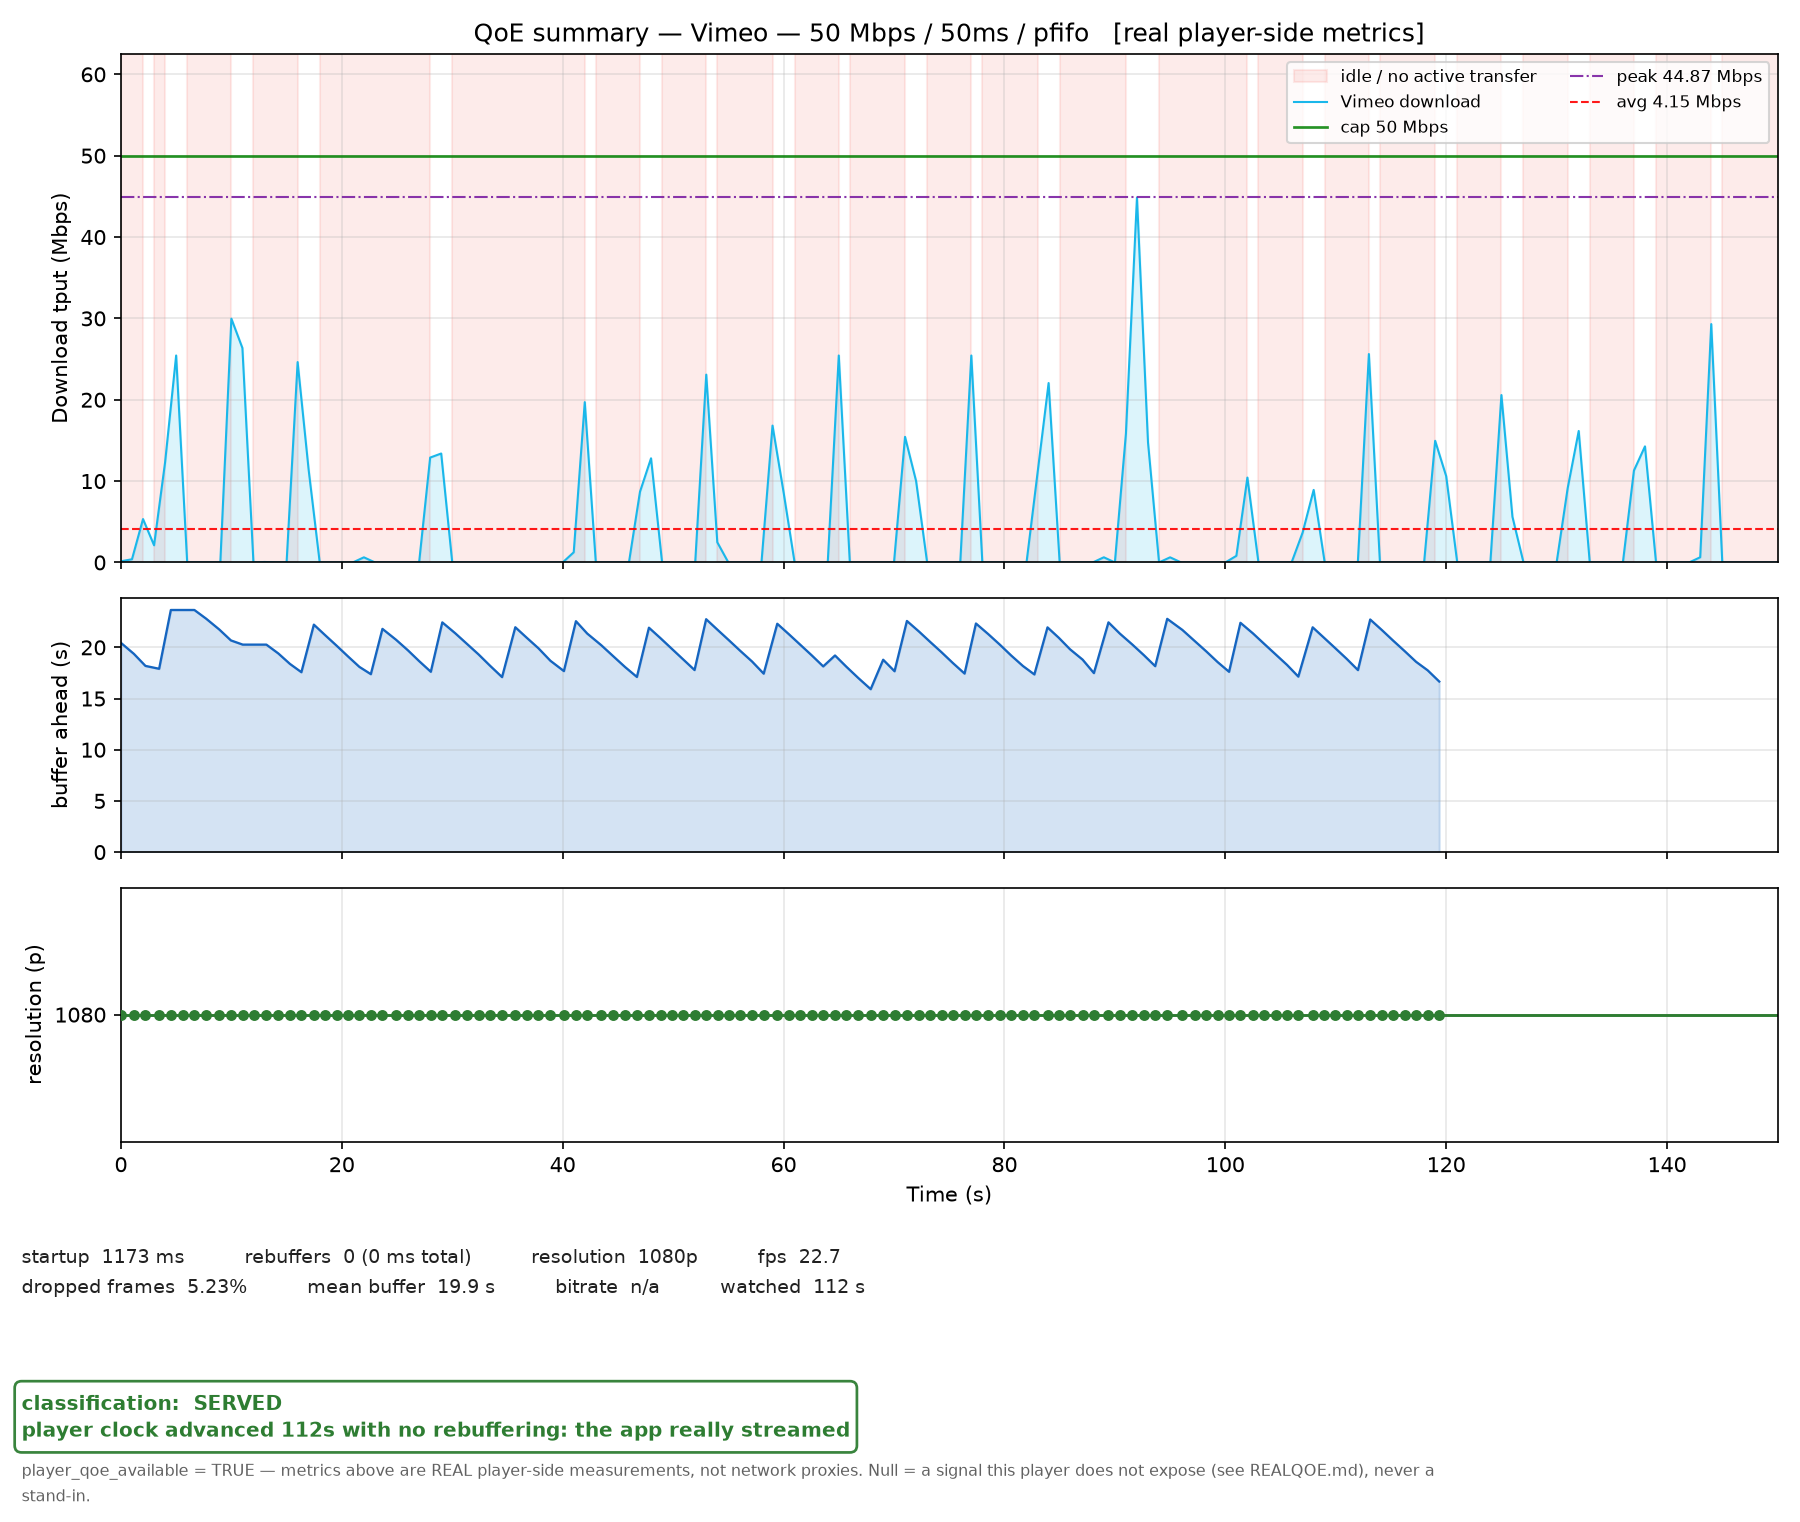

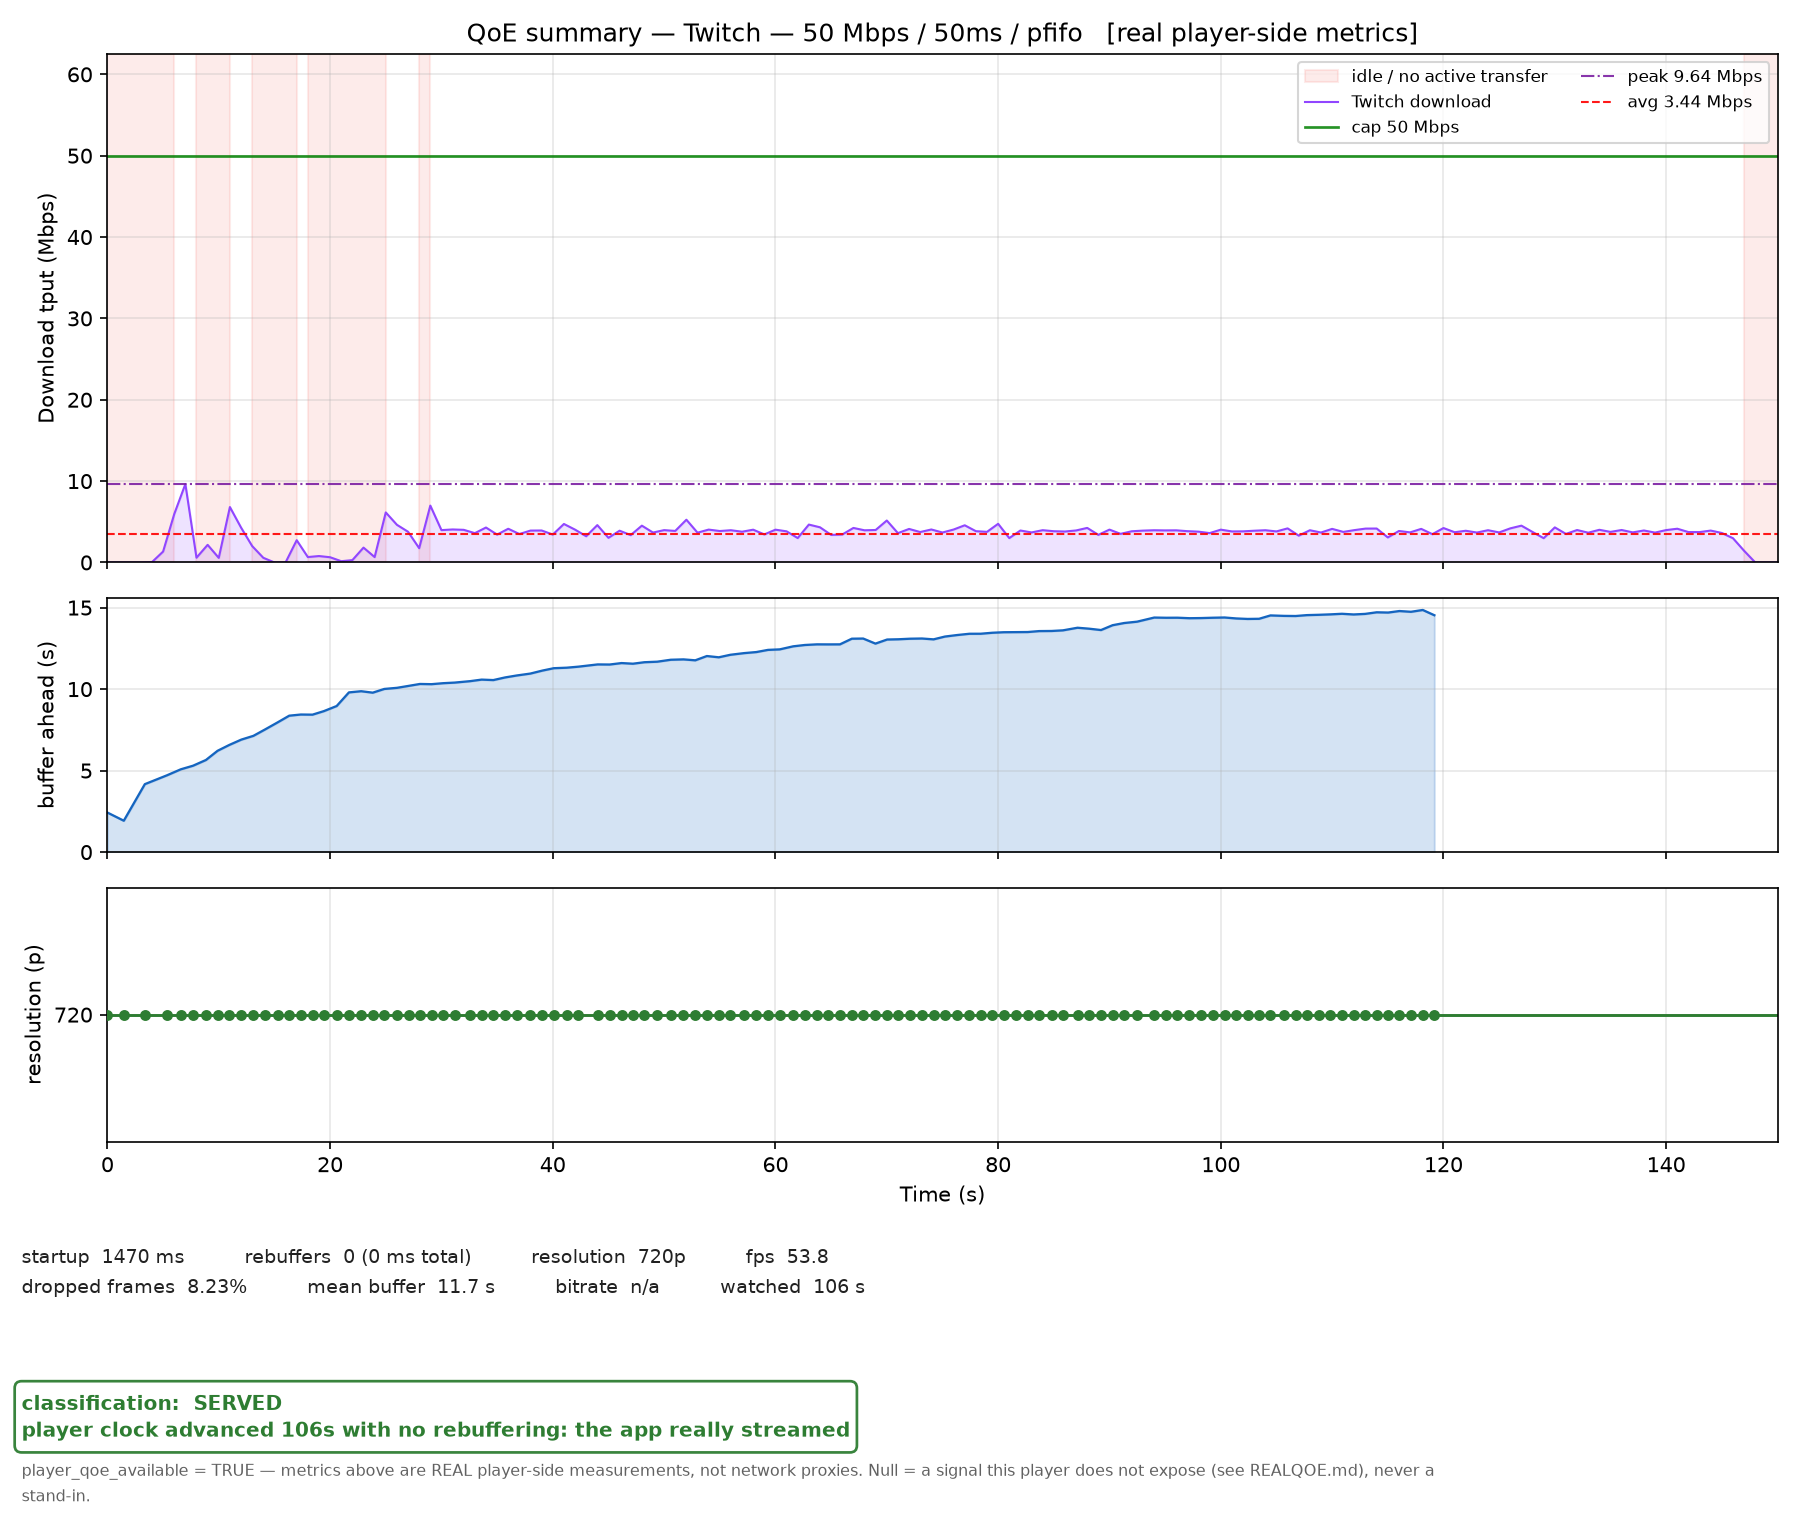

In [6]:
# Per-app QoE summaries from the run above.
for app in concurrent_cfg.apps:
    png = run_dir / f"qoe_summary_{app}.png"
    if png.exists():
        display(Image(filename=str(png)))


### Real player-side QoE

Every browser app in the run is driven in **real headed Chrome** (Xvfb +
SeleniumBase/undetected-chromedriver), launched *inside the substrate worker's
shaped `ns1` namespace* so its traffic is genuinely rate-limited and captured.
Per-second player samples are reduced by `shared/qoe.py` into the `QoEMetrics`
fields defined in `shared/models/README.md`.

`n/a` in the table below means the player genuinely does not expose that signal
for that app — see `REALQOE.md` for the per-app matrix. It is never a
placeholder. In particular **bitrate stays null unless it is truly byte-derived**:
YouTube's `bandwidth_kbps` is a connection-speed estimate, not the media bitrate,
and is reported separately as `connection_speed_estimate_mbps`.

Apps that need a remote video peer (Meet, Zoom) are marked `skipped` with a
reason rather than measured against their own local camera preview, and the rest
of the run still succeeds.

In [7]:
# Real per-app QoE for the most recent run (no browser code here — the
# collector runs on the VM; this is just the client view).
ph.show_player_qoe(concurrent_record)

Real player-side QoE — player_qoe_available = True
  source: real Chrome driven inside the shaped ns1 namespace; metrics per shared/models/README.md QoEMetrics



,app,status,resolution,startup,rebuffers,rebuf_time,dropped,fps,bitrate,buffer,watched
0,youtube,ok,360p,2916 ms,0,0 ms,0.89%,24.8,n/a,84 s,113 s
1,vimeo,ok,1080p,1173 ms,0,0 ms,5.23%,22.7,n/a,19.9 s,112 s
2,twitch,ok,720p,1470 ms,0,0 ms,8.23%,53.8,n/a,11.7 s,106 s


,app,status,resolution,startup,rebuffers,rebuf_time,dropped,fps,bitrate,buffer,watched
0,youtube,ok,360p,2916 ms,0,0 ms,0.89%,24.8,n/a,84 s,113 s
1,vimeo,ok,1080p,1173 ms,0,0 ms,5.23%,22.7,n/a,19.9 s,112 s
2,twitch,ok,720p,1470 ms,0,0 ms,8.23%,53.8,n/a,11.7 s,106 s


## 4 · Full parameter sweep — **OPTIONAL** · ~45 min · does NOT run by default

The broad matrix: bandwidth x latency x loss x AQM x contention, plus the
household tiers (50 / 100 Mbps) and the equity pair. 19 runs at ~2.3 min each.

This is deliberately gated. §2 gives reference numbers in ~12 minutes; run this
only when you want the complete parameter space — for a paper figure, or after a
change that could plausibly move results across the whole matrix.

**To run it:** set `RUN_FULL_SWEEP = True` in the next cell, then execute §4.
Everything it produces goes through the same capture / attribution / `record.json`
path as the baseline, and is validated identically (§5).


In [8]:
# Opt-in switch for §4. Left False so "Run All" stays fast (~12 min, §2 only).
RUN_FULL_SWEEP = False            # <- set True to run the full ~45 min matrix

from pathlib import Path
cmp_dir = ph.RESULTS_ROOT / "comparisons"   # shared by the sweep cells below
print("full sweep ENABLED (~45 min)" if RUN_FULL_SWEEP
      else "full sweep disabled — baseline (§2) is the fast path")


full sweep disabled — baseline (§2) is the fast path


### 4.1 · AQM comparison — pfifo vs fq_codel (same everything else)


In [9]:
if not RUN_FULL_SWEEP:
    print('skipped — set RUN_FULL_SWEEP = True in the cell above to run this')
else:
    from pathlib import Path

    AQM_APPS = ["youtube", "vimeo"]
    aqm_records = {}
    for aqm in ["pfifo", "fq_codel"]:
        cfg_aqm = ExperimentConfig(
            apps=AQM_APPS, bandwidth_mbps=6, latency_ms=50,
            aqm=aqm, cca="cubic", duration_s=60, controller=CONTROLLER, tag="aqm_cmp",
        )
        aqm_records[aqm] = [run_experiment(cfg_aqm, mode="direct")]

    cmp_dir = ph.RESULTS_ROOT / "comparisons"

    # Per app — this is the fairness comparison that matters.
    for app in AQM_APPS:
        ph.plot_aqm_comparison(
            aqm_records, cmp_dir / f"aqm_pfifo_vs_fqcodel_throughput_{app}.png",
            metric="avg_throughput_mbps", app=app)
        ph.plot_aqm_comparison(
            aqm_records, cmp_dir / f"aqm_pfifo_vs_fqcodel_delivered_{app}.png",
            metric="delivered_fraction", app=app)


skipped — set RUN_FULL_SWEEP = True in the cell above to run this


### 4.2 · Parameter sweeps — bandwidth, latency, contention


In [10]:
if not RUN_FULL_SWEEP:
    print('skipped — set RUN_FULL_SWEEP = True in the cell above to run this')
else:
    # ── QoE vs BANDWIDTH (find the cliff) ────────────────────────────────────
    base = ExperimentConfig(apps=["youtube"], latency_ms=0, aqm="pfifo",
                            cca="cubic", duration_s=60, controller=CONTROLLER,
                            tag="sweep_bw")

    bw_records = run_sweep(base, "bandwidth_mbps", [1, 3, 6, 10, 25], mode="direct")

    cmp_dir = ph.RESULTS_ROOT / "comparisons"
    # How much each tier actually delivers to the app, and how close to the cap.
    ph.plot_throughput_vs_bandwidth(bw_records, cmp_dir / "throughput_vs_bw.png",
                                    app="youtube")
    ph.plot_qoe_vs_bandwidth(bw_records, cmp_dir / "delivered_vs_bw.png",
                             metric="delivered_fraction", app="youtube")
    ph.plot_qoe_vs_bandwidth(bw_records, cmp_dir / "peak_vs_bw.png",
                             metric="peak_throughput_mbps", app="youtube")


skipped — set RUN_FULL_SWEEP = True in the cell above to run this


In [11]:
if not RUN_FULL_SWEEP:
    print('skipped — set RUN_FULL_SWEEP = True in the cell above to run this')
else:
    # ── QoE vs LATENCY (does RTT hurt more than bandwidth?) ──────────────────
    base_lat = ExperimentConfig(apps=["youtube"], bandwidth_mbps=10, aqm="pfifo",
                                cca="cubic", duration_s=60, controller=CONTROLLER,
                                tag="sweep_lat")

    lat_records = run_sweep(base_lat, "latency_ms", [0, 25, 50, 100, 200], mode="direct")

    ph.plot_qoe_vs_latency(lat_records, cmp_dir / "throughput_vs_latency.png",
                           metric="avg_throughput_mbps", app="youtube")
    ph.plot_qoe_vs_latency(lat_records, cmp_dir / "stalls_vs_latency.png",
                           metric="stall_seconds", app="youtube")


skipped — set RUN_FULL_SWEEP = True in the cell above to run this


In [12]:
if not RUN_FULL_SWEEP:
    print('skipped — set RUN_FULL_SWEEP = True in the cell above to run this')
else:
    # ── QoE vs CONCURRENCY (who gets starved first: 1 vs 2 vs 3 apps) ─────────
    conc_sets = [["youtube"], ["youtube", "vimeo"], ["youtube", "vimeo", "twitch"]]
    conc_records = []
    for apps in conc_sets:
        cfg_c = ExperimentConfig(apps=apps, bandwidth_mbps=6, latency_ms=50,
                                 aqm="pfifo", cca="cubic", duration_s=60,
                                 controller=CONTROLLER, tag="sweep_conc")
        rec = run_experiment(cfg_c, mode="direct")
        if rec:
            conc_records.append(rec)

    # YouTube is in every set, so its curve shows what contention costs *one* app.
    ph.plot_qoe_vs_concurrency(conc_records, cmp_dir / "throughput_vs_concurrency.png",
                               metric="avg_throughput_mbps", app="youtube")
    ph.plot_qoe_vs_concurrency(conc_records, cmp_dir / "delivered_vs_concurrency.png",
                               metric="delivered_fraction", app="youtube")


skipped — set RUN_FULL_SWEEP = True in the cell above to run this


### 4.3 · Equity comparison — well-served vs redlined household


In [13]:
if not RUN_FULL_SWEEP:
    print('skipped — set RUN_FULL_SWEEP = True in the cell above to run this')
else:
    HOUSEHOLD = ["youtube", "vimeo"]   # same apps + size for both profiles

    well_served = run_experiment(ExperimentConfig(
        apps=HOUSEHOLD, bandwidth_mbps=100, latency_ms=10, aqm="fq_codel",
        cca="cubic", duration_s=60, controller=CONTROLLER, tag="equity_well"),
        mode="direct")

    redlined = run_experiment(ExperimentConfig(
        apps=HOUSEHOLD, bandwidth_mbps=3, latency_ms=100, aqm="pfifo",
        cca="cubic", duration_s=60, controller=CONTROLLER, tag="equity_redlined"),
        mode="direct")

    # Headline equity plot, drawn per app so the gap is attributable.
    for app in HOUSEHOLD:
        ph.plot_equity_comparison(well_served, redlined,
                                  cmp_dir / f"equity_throughput_{app}.png",
                                  metric="avg_throughput_mbps", app=app)
        ph.plot_equity_comparison(well_served, redlined,
                                  cmp_dir / f"equity_delivered_{app}.png",
                                  metric="delivered_fraction", app=app)


skipped — set RUN_FULL_SWEEP = True in the cell above to run this


## 5 · Dataset & history

`load_dataset()` flattens every DIRECT run from
`results/pramana_runs/dataset_index.jsonl` into **one row per app per run**,
carrying that app's own throughput in its plotted direction plus its
`served` / `starved` classification. The combined link total is deliberately not
a column — it is not a per-app measurement.

`show_history()` lists the most recent rows the telemetry service has stored.


In [14]:
from IPython.display import display

df = ph.load_dataset()          # one row per app per run
if df is not None:
    display(df)

ph.show_history(limit=15)       # recent rows from the telemetry service

# Bring an older run folder up to the per-app convention (re-splits its pcap and
# rewrites its record.json + plots — no re-run needed):
# ph.replot_run("results/pramana_runs/<slug>_<id>")


,slug,apps,concurrency,bandwidth_mbps,latency_ms,loss_pct,aqm,cca,shaping_verified,workflow_ok,...,fps,bitrate_mbps,avg_throughput_mbps,peak_throughput_mbps,p95_throughput_mbps,total_mb,stall_seconds,delivered_fraction,classification,attribution
0,youtube_6mbps_50ms_0pct_pfifo_cubic_solo_t1,youtube,solo,6.0,50.0,0.0,pfifo,cubic,True,True,...,24.97,None,1.595,5.897,5.565,14.953,23.0,0.693,served,remote_hostname
1,youtube_6mbps_50ms_0pct_pfifo_cubic_solo_t1,youtube,solo,6.0,50.0,0.0,pfifo,cubic,True,True,...,24.53,None,1.623,5.832,5.583,14.813,22.0,0.699,served,remote_hostname
2,youtube+vimeo_6mbps_50ms_0pct_pfifo_cubic_conc...,youtube+vimeo,concurrent2,6.0,50.0,0.0,pfifo,cubic,True,True,...,24.99,None,1.535,4.788,4.208,18.418,7.0,0.927,served,remote_hostname
3,youtube+vimeo_6mbps_50ms_0pct_pfifo_cubic_conc...,youtube+vimeo,concurrent2,6.0,50.0,0.0,pfifo,cubic,True,True,...,23.85,None,1.254,2.568,2.281,15.043,7.0,0.927,served,remote_hostname
4,youtube+vimeo_6mbps_50ms_0pct_pfifo_cubic_conc...,youtube+vimeo,concurrent2,6.0,50.0,0.0,pfifo,cubic,True,True,...,24.99,None,0.453,5.713,3.845,5.384,82.0,0.137,served,remote_hostname
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
261,youtube+vimeo+twitch_10mbps_50ms_0pct_pfifo_cu...,youtube+vimeo+twitch,concurrent3,10.0,50.0,0.0,pfifo,cubic,True,True,...,15.91,None,4.430,8.390,7.331,85.834,22.0,0.858,served,remote_hostname
262,youtube+vimeo+twitch_10mbps_50ms_0pct_pfifo_cu...,youtube+vimeo+twitch,concurrent3,10.0,50.0,0.0,pfifo,cubic,True,True,...,40.14,None,2.482,8.244,4.421,48.084,13.0,0.916,served,remote_hostname
263,youtube+vimeo+twitch_50mbps_50ms_0pct_pfifo_cu...,youtube+vimeo+twitch,concurrent3,50.0,50.0,0.0,pfifo,cubic,True,True,...,24.82,None,0.315,12.472,0.511,5.939,144.0,0.046,served,remote_hostname
264,youtube+vimeo+twitch_50mbps_50ms_0pct_pfifo_cu...,youtube+vimeo+twitch,concurrent3,50.0,50.0,0.0,pfifo,cubic,True,True,...,22.70,None,4.151,44.865,25.440,78.347,114.0,0.245,served,remote_hostname


15 most recent experiment(s) in telemetry:


,when,app,status,capacity (Mbps),latency (ms),throughput (Mbps)
0,2026-09-11 18:17:37,exp-58e7eb0e2c,success,50,50,3.445
1,2026-09-11 18:17:37,exp-58e7eb0e2c,success,50,50,4.151
2,2026-09-11 18:17:37,exp-58e7eb0e2c,success,50,50,0.315
3,2026-09-11 18:13:43,exp-34918b6291,success,10,50,2.482
4,2026-09-11 18:13:43,exp-34918b6291,success,10,50,4.43
5,2026-09-11 18:13:43,exp-34918b6291,success,10,50,0.807
6,2026-09-11 18:07:44,exp-9491b65f8e,success,6,50,1.252
7,2026-09-11 18:07:44,exp-9491b65f8e,success,6,50,2.5
8,2026-09-11 18:07:44,exp-9491b65f8e,success,6,50,1.055
9,2026-09-11 18:01:34,exp-36cd7f2771,success,3,50,0.778


,when,app,status,capacity (Mbps),latency (ms),throughput (Mbps)
0,2026-09-11 18:17:37,exp-58e7eb0e2c,success,50,50,3.445
1,2026-09-11 18:17:37,exp-58e7eb0e2c,success,50,50,4.151
2,2026-09-11 18:17:37,exp-58e7eb0e2c,success,50,50,0.315
3,2026-09-11 18:13:43,exp-34918b6291,success,10,50,2.482
4,2026-09-11 18:13:43,exp-34918b6291,success,10,50,4.43
5,2026-09-11 18:13:43,exp-34918b6291,success,10,50,0.807
6,2026-09-11 18:07:44,exp-9491b65f8e,success,6,50,1.252
7,2026-09-11 18:07:44,exp-9491b65f8e,success,6,50,2.5
8,2026-09-11 18:07:44,exp-9491b65f8e,success,6,50,1.055
9,2026-09-11 18:01:34,exp-36cd7f2771,success,3,50,0.778


## How to run this on the lab VM

Full setup, including building the collector image, is in
[`experiments/pramana/README.md`](README.md). Short version:

### Option A — run Jupyter on the VM (recommended)
```bash
# 1) SSH in
ssh -p 2204 student@128.111.5.230

# 2) clone this repo and bring the stack up
git clone https://github.com/sthanavm/agentic-thin-waist.git
cd agentic-thin-waist
cp .env.example .env
docker compose up -d postgres telemetry-service substrate-worker
#    DIRECT mode needs substrate-worker(:8002) + telemetry-service(:8004).

# 3) build the real-Chrome QoE collector (once, ~2 GB)
docker build -t video-qoe-collector:latest \
  services/orchestration/scripts/selenium_video_qoe/

# 4) deps + Jupyter, then launch bound to localhost
pip install -r experiments/pramana/requirements.txt
jupyter notebook --no-browser --port 8888
```
Then tunnel the Jupyter port from your laptop and open the printed URL:
```bash
ssh -p 2204 -L 8888:localhost:8888 student@128.111.5.230
```
Open `experiments/pramana/pramana_demo.ipynb`.

**Which cells to run**

| | what | time |
|---|---|---|
| §2 Baseline | fixed reference scenarios; runs on *Run All* | ~12 min |
| §4 Full sweep | whole parameter matrix; opt-in via `RUN_FULL_SWEEP = True` | ~45 min |

*Run All* executes §2 only. §4 stays skipped until you flip the switch, so opening the notebook never commits you to the long matrix.

### Option B — notebook on your laptop, services tunnelled
```bash
ssh -p 2204 student@128.111.5.230 \
  -L 8002:localhost:8002 -L 8004:localhost:8004
```
The stack is driven over HTTP and the pcap is downloaded over HTTP, so the
network side works. **Player QoE does not** — the collector is launched with
`docker run` on the machine running this notebook, and it must join the substrate
worker's `ns1` namespace, which only exists on the VM. Use Option A for real QoE.

### Non-interactive runs (long sweeps)
```bash
tmux new -s pramana
papermill experiments/pramana/pramana_demo.ipynb out.ipynb \
  -p RUN_FULL_SWEEP true      # omit to run the ~12 min baseline only
```

Results land under `experiments/pramana/results/pramana_runs/` (gitignored) —
one folder per run with `capture.pcap`, `record.json`, `qoe/<app>_stats.jsonl`,
and per-app `throughput_<app>.png` + `qoe_summary_<app>.png`.
